<center><h1> ESNGrad <h1><center>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

%cd "/content/drive/MyDrive/RC-Diffusion Project/RC-Diffusion-Models-for-Time-Series-Generation"
# !pip install -q lightning torchmetrics formulaic interface_meta statsmodels
# !pip install -q -e . --no-deps


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/RC-Diffusion Project/RC-Diffusion-Models-for-Time-Series-Generation


In [2]:
import torch 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
from pathlib import Path
from tqdm import tqdm 

# Table of Contents
* [Intro](#Introduction)
* [Data](#Data)
* [Model Specifications](#Model-Specifications)
    * [Diffusion Process](#Diffusion-Process)
    * [Encoding Network](#ESN)
    * [Denoiser Network](#Denoiser-Network)
    * [Training Specification](#Specs)
    * [Finalizing a Time-Series Diffusion Model](#TSdiff)
* [Training](#Training)
* [Testing](#Testing)

# Introduction

We try a simple forecast of the RV as in the paper. 

# Data

In the paper they use `2000` obs as training set and a bit more than `2000` as test set. They use both $RV_t$ and $\ln(RV_t)$ as target variables. 

In [25]:
RV_PATH = 'data/SP500_RV_5min.xlsx'
PATH_RUNS = Path('runs')


STANDARDIZE = False 
LOG = True
N_TRAIN = 2000

raw = pd.read_excel(RV_PATH)
raw['Date'] = pd.to_datetime(raw['Date'], format='%Y%m%d')
dates = raw['Date'].to_numpy()
rv = raw['RV']
rv = torch.tensor(raw['RV'].to_numpy(), dtype=torch.float32).reshape(-1, 1)

rv_train = rv[:N_TRAIN]
rv_test = rv[N_TRAIN:]
dates_train = dates[:N_TRAIN]
dates_test = dates[N_TRAIN:]

def print_stats(x : torch.Tensor, txt : str): 
    print("****")
    print(txt)
    print('Mean :', x.mean(dim = 0).item())
    print('Standard Deviation :', x.std(dim = 0).item())
    print('Skweness :',((x - x.mean(dim = 0)) / (x.std(dim = 0) + 1e-8)**3).mean(dim = 0))
    print("****")

print_stats(rv_train, 'Stats for simple RV train set')
print_stats(rv_test, 'Stats for simple RV test set')

if LOG:
    rv_train = torch.log(rv_train)
    rv_test = torch.log(rv_test)
    PATH_RUNS = PATH_RUNS / 'rv_log'
    print_stats(rv_train, 'Stats after log transform for train set')
    print_stats(rv_test, 'Stats after log transform for test set')
else: 
    PATH_RUNS = PATH_RUNS / 'rv'

if STANDARDIZE:
    mu, std = rv_train.mean(dim = 0), rv_train.std(dim = 0)
    rv_train = (rv_train - mu)/std
    rv_test = (rv_test - mu)/std
    PATH_RUNS = PATH_RUNS / 'std'
    print_stats(rv_train, 'Stats after standardization for train set')
    print_stats(rv_test, 'Stats after standardization for test set')

if not PATH_RUNS.exists(): 
    raise ValueError('The directory to save the runs does not exists')
else: 
    print('Runs will be saved under: ', PATH_RUNS)

****
Stats for simple RV train set
Mean : 1.1942918300628662
Standard Deviation : 1.5430175065994263
Skweness : tensor([1.8001e-08])
****
****
Stats for simple RV test set
Mean : 1.1570228338241577
Standard Deviation : 2.864265203475952
Skweness : tensor([4.7490e-09])
****
****
Stats after log transform for train set
Mean : -0.18863756954669952
Standard Deviation : 0.8047213554382324
Skweness : tensor([3.7909e-08])
****
****
Stats after log transform for test set
Mean : -0.6357990503311157
Standard Deviation : 1.068070411682129
Skweness : tensor([1.5925e-08])
****
Runs will be saved under:  runs/rv_log


# Model Specifications

Here we can customized the models. A time series diffusion model, in our context, is the combination of three components: 

* A **diffusion process** (e.g. DDPM, DDIM, SDE VE, SDE VP, SDE/ODE, etc.) defines the **forward** and the **reverse** process of the generative model. From the codebase: `rcdiff/diff/` contains different forward and reverse processes. 

* A **temporal encoder model** (e.g. RNNs, Transformers, ESN) that summarizes the temporal dependency of the time-series and acts as a conditioning in the estimation of the noise (i.e. conditional score). Here we only focus on ESNs. From the codebase: `rcdiff/models/encoders` contains the ESN module. 

* A **denoiser network** $\epsilon_{\theta}(x^{k}_{t},s_{t-1}, k)$ that estimates at each step $k$ of the process, the amount of corruption added by the diffusion process. Here we only focus on a simple MLP. From the codebase: `rcdiff/models/denoisers` contains the denoiser module. 


## Diffusion Process

First we need to define our diffusion process. We use the standard `DDPM`. 

In [26]:
from rcdiff.diff import DDPM, BaseScheduler
from rcdiff.models.config import build_diffusion, DiffusionConfig

K = 100

diffConfig = DiffusionConfig(num_timesteps = K, 
                beta_1 = 1e-4, 
                beta_K = 0.1,
                mode = "linear",
                s = 0.008,
                process = 'ddpm'
                )

## ESN

Second, we need to define the encoder network. We use the `ESN` module and sample the parameters: 

In [ ]:
from rcdiff import ESN, RandomWeight, ParametersESN
from rcdiff.models.config import ESNConfig, build_esn, RandomWeightConfig

R = 25 
T, N = rv_train.shape

A = RandomWeightConfig(dist="normal", sparsity=0., norm_type="spectral_radius")
C = RandomWeightConfig(dist="uniform", sparsity=0., norm_type="l2")
zeta = RandomWeightConfig(dist="uniform", sparsity=0.2, norm_type="euclidean")

esnConfig = ESNConfig(reservoir_size = R, 
                A = A, 
                C = C,
                zeta = zeta,
                leak_rate = 0.3, # 0
                rho = 0.9, # NOTE: to high? 
                gamma = 0.35, 
                omega = 0
                ) 

## Denoiser Network

Then we need to define the denoiser network. Here we use the `SimpleMLP` network

In [43]:
from rcdiff.models.denoisers import SimpleMLP 
from rcdiff.models.config import DenoiserConfig

denoiserConfig = DenoiserConfig("simple_mlp", {"dim_hids": [32, 32], "time_dim": 128})

## Specs

Here we then define the training characteristics of the network: 

In [44]:
from rcdiff.models.config import TrainConfig

t0 = 100

train_spec = TrainConfig(t0 = t0,                            
    batch_size = 526,
    lr = 1e-3,
    max_iters = 1000,
    val_fraction = 0.25, 
    eval_every = 1,
    patience = 100,  
    ema_decay = 0.99,  
    grad_clip = 1.0,
    seed = 3245,
    device = "cpu")

## TSdiff

In [45]:
from rcdiff.models.config import ExperimentConfig, build_diffusion, build_denoiser, build_esn
from rcdiff.models import ESNGrad

cfg = ExperimentConfig(name="rv_simple", 
                       in_dim=1,
                       n_covariates = 0,
                       esn = esnConfig,
                       denoiser = denoiserConfig,
                       diffusion = diffConfig,
                       train = train_spec
                       )


# path = PATH_RUNS / 'esn_good_run.yaml'
# cfg.to_yaml(path)

## Load directly from yaml file

In [221]:
# cfg = ExperimentConfig.from_yaml('runs/rv_log/best_run.yaml')

In [46]:
model = ESNGrad(diff=build_diffusion(cfg), 
                esn=build_esn(cfg),
                denoiser=build_denoiser(cfg), 
                spec=cfg.train
                )

# Training

Early stopping at iteration 344 | best val loss 0.1980


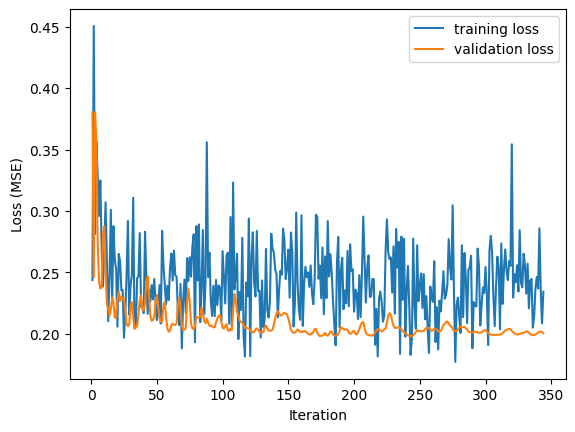

In [48]:
loss, time = model.fit(x = rv_train, c = None)

plt.plot(loss['iter'], loss['train'], label = 'training loss')
plt.plot(loss['iter'], loss['val'], label = 'validation loss')
plt.ylabel('Loss (MSE)')
plt.xlabel('Iteration')
plt.legend()
plt.show()

In [224]:
# model.save_checkpoint(path = 'runs/rv_log/best_model.pth', cfg = cfg)

In [ ]:
in_sample_predictions = model.in_sample_check(x_train = rv_train, c_train = None, n_samples = 100, chunk_size = 100)

In-sample check: 100%|██████████| 19/19 [01:26<00:00,  4.57s/it]


prediction mean -0.24189603328704834
Actual mean -0.18863756954669952
prediction std 0.7797296047210693
Actual std 0.8047213554382324


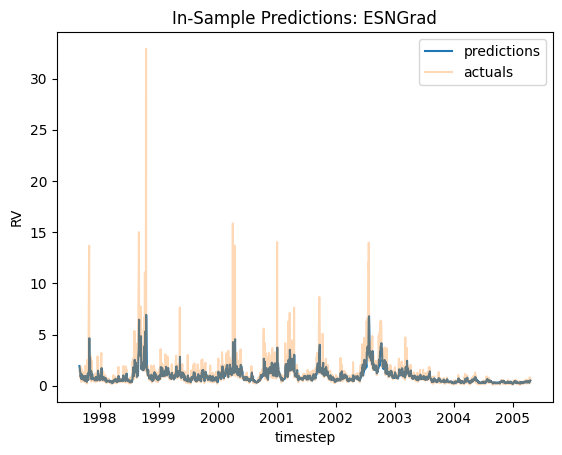

In [36]:
mean_in_sample = in_sample_predictions.mean(dim = 1)

if LOG: 
   predictions_df = pd.DataFrame({'predictions' : np.exp(mean_in_sample.detach().numpy().flatten()), 
                                 'true' : np.exp(rv_train[100:].detach().numpy().flatten())}, 
                              index = dates_train[100:]
                              )
else: 
   predictions_df = pd.DataFrame({'predictions' : mean_in_sample.detach().numpy().flatten(), 
                              'true' : rv_train[100:].detach().numpy().flatten()}, 
                           index = dates_train[100:]
                           )
      
print('prediction mean', in_sample_predictions.flatten().mean().item())
print('Actual mean', rv_train.flatten().mean().item())
print('prediction std', in_sample_predictions.flatten().std().item())
print('Actual std', rv_train.flatten().std().item())

plt.title('In-Sample Predictions: ESNGrad')
plt.plot(predictions_df.index, predictions_df['predictions'], label = 'predictions')
plt.plot(predictions_df.index, predictions_df['true'], label = 'actuals', alpha = 0.3)
plt.ylabel('RV')
plt.xlabel('timestep')
plt.legend()
plt.show()

# Test

Using the `conditional_distribution` method you can sample from $p(x_t|s_{t-1})$ 

In [37]:
x_hat, process_history = model.conditional_distribution(x = rv_train, c = None, n_samples=100)

Actual: -0.397 Predicted: -0.864


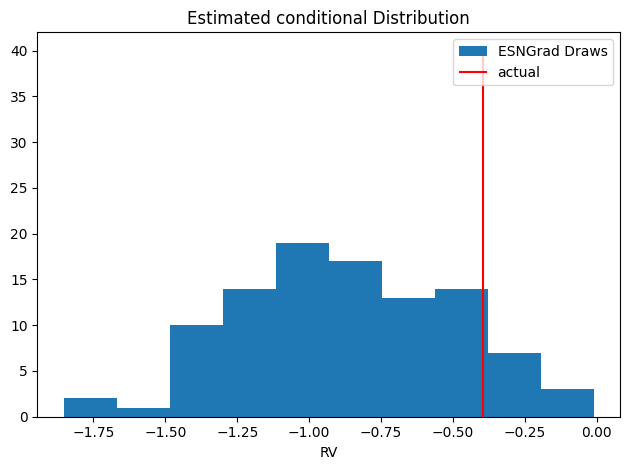

In [38]:
print('Actual:', round(rv_test[0].item(),3), 'Predicted:', round(x_hat.mean(dim = 0).item(),3))

plt.title('Estimated conditional Distribution')
plt.hist(x_hat.detach().numpy(), bins = 10, label = 'ESNGrad Draws')
plt.vlines(x = rv_test[0], ymin = 0, ymax = 40, color = 'red', label = 'actual')
plt.xlabel('RV')
plt.legend()
plt.tight_layout()
plt.show()

using the `one_step_ahead_forecast` you perform a one-step ahead forecast in a recursive way

In [ ]:
forecast = model.one_step_ahead_forecast(x_train = rv_train, 
                                         x_test = rv_test,
                                         chunk_size = 200, 
                                         n_samples = 200)

 27%|██▋       | 3/11 [07:46<20:34, 154.28s/it]

In [230]:
save = True 
path_save = PATH_RUNS / 'run_5.pt'

if save: 
    torch.save(forecast, path_save)

# forecast = torch.load(path_save, weights_only=True)

In [ ]:
F_m = forecast.squeeze(2).mean(dim = 1)

if LOG:
    F = torch.exp(F_m)
    test = torch.exp(rv_test)
else: 
    F = F_m.clone()
    test = rv_test.clone()

def qlike(actual, pred):
    r = actual/pred
    return torch.mean(r-torch.log(r)-1)

def mse(actual, pred):
    return torch.mean((actual-pred)**2)

def mae(actual, pred):
    return torch.mean(torch.abs(actual-pred))


mse_test = mse(test.squeeze(1), F)
mae_test = mae(test.squeeze(1), F)
qlike_test = qlike(test.squeeze(1), F)

print('MSE of the test:', mse_test)
print('MAE of the test:', mae_test)
print('QLIKE of the test:', qlike_test)

MSE of the test: tensor(4.1828)
MAE of the test: tensor(0.5012)
QLIKE of the test: tensor(0.1562)


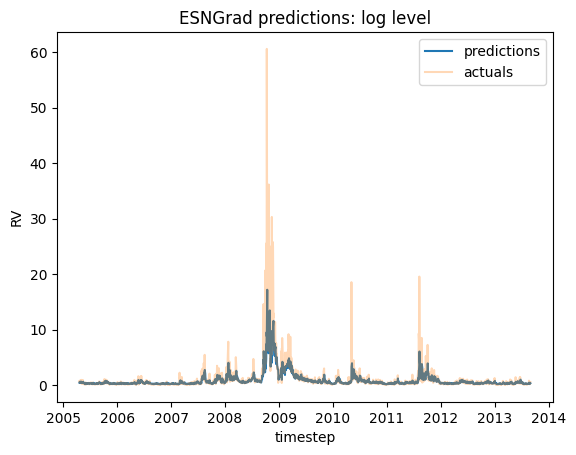

In [ ]:
predictions_df = pd.DataFrame({'predictions' : F.detach().numpy().flatten(), 
                               'true' : test.detach().numpy().flatten()}, 
                            index = dates_test
                            )

plt.title('ESNGrad predictions: log level')
plt.plot(predictions_df.index, predictions_df['predictions'], label = 'predictions')
plt.plot(predictions_df.index, predictions_df['true'], label = 'actuals', alpha = 0.3)
plt.ylabel('RV')
plt.xlabel('timestep')
plt.legend()
plt.show()

# Brute Force: Grid Search on ESN

In [16]:
save_dir = Path('runs/forced')
RV_PATH = 'data/SP500_RV_5min.xlsx'


STANDARDIZE = False 
LOG = True
N_TRAIN = 2000

raw = pd.read_excel(RV_PATH)
raw['Date'] = pd.to_datetime(raw['Date'], format='%Y%m%d')
dates = raw['Date'].to_numpy()
rv = torch.tensor(raw['RV'].to_numpy(), dtype=torch.float32).reshape(-1, 1)

rv_train = rv[:N_TRAIN]
rv_test = rv[N_TRAIN:]
dates_train = dates[:N_TRAIN]
dates_test = dates[N_TRAIN:]

def print_stats(x : torch.Tensor, txt : str): 
    print("****")
    print(txt)
    print('Mean :', x.mean(dim = 0).item())
    print('Standard Deviation :', x.std(dim = 0).item())
    print('Skweness :',((x - x.mean(dim = 0)) / (x.std(dim = 0) + 1e-8)**3).mean(dim = 0))
    print("****")

print_stats(rv_train, 'Stats for simple RV train set')
print_stats(rv_test, 'Stats for simple RV test set')

if LOG:
    rv_train = torch.log(rv_train)
    rv_test = torch.log(rv_test)
    PATH_RUNS = PATH_RUNS / 'rv_log'
    print_stats(rv_train, 'Stats after log transform for train set')
    print_stats(rv_test, 'Stats after log transform for test set')
else: 
    PATH_RUNS = PATH_RUNS / 'rv'

if STANDARDIZE:
    mu, std = rv_train.mean(dim = 0), rv_train.std(dim = 0)
    rv_train = (rv_train - mu)/std
    rv_test = (rv_test - mu)/std
    PATH_RUNS = PATH_RUNS / 'std'
    print_stats(rv_train, 'Stats after standardization for train set')
    print_stats(rv_test, 'Stats after standardization for test set')

if not save_dir.exists(): 
    raise ValueError('The directory to save the runs does not exists')
else: 
    print('Runs will be saved under: ', save_dir)

****
Stats for simple RV train set
Mean : 1.1942918300628662
Standard Deviation : 1.5430175065994263
Skweness : tensor([1.8001e-08])
****
****
Stats for simple RV test set
Mean : 1.1570228338241577
Standard Deviation : 2.864265203475952
Skweness : tensor([4.7490e-09])
****
****
Stats after log transform for train set
Mean : -0.18863756954669952
Standard Deviation : 0.8047213554382324
Skweness : tensor([3.7909e-08])
****
****
Stats after log transform for test set
Mean : -0.6357990503311157
Standard Deviation : 1.068070411682129
Skweness : tensor([1.5925e-08])
****
Runs will be saved under:  runs/forced


0it [00:00, ?it/s]

Run No: 0
Run Name test_0
Estimating the model...



0it [00:07, ?it/s]                                                                                                          

Early stopping at iteration 313 | best val loss 0.1996
Out of sample...


100%|██████████| 11/11 [02:04<00:00, 11.33s/it]


Result of run  0
(100, 25, 0.9, 0.3, 0.2)
MSE of the test: 3.5743305683135986
MAE of the test: 0.47898200154304504
QLIKE of the test: 0.14653638005256653


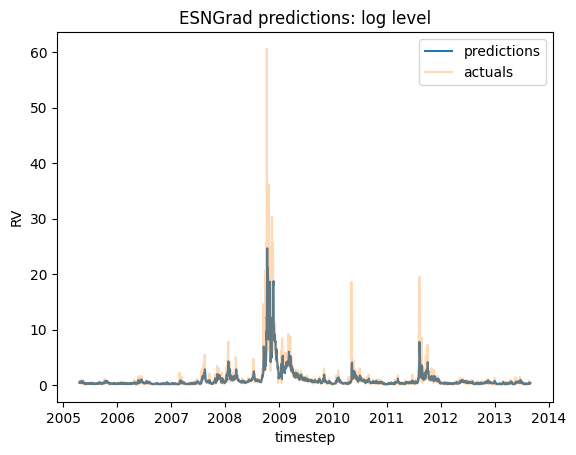

1it [02:12, 132.65s/it]

Run No: 1
Run Name test_1
Estimating the model...



1it [02:24, 132.65s/it]                                                                                                     

Early stopping at iteration 558 | best val loss 0.1968
Out of sample...


100%|██████████| 11/11 [02:04<00:00, 11.29s/it]


Result of run  1
(100, 25, 0.9, 0.3, 0.25)
MSE of the test: 3.5995659828186035
MAE of the test: 0.4783826768398285
QLIKE of the test: 0.1471414566040039


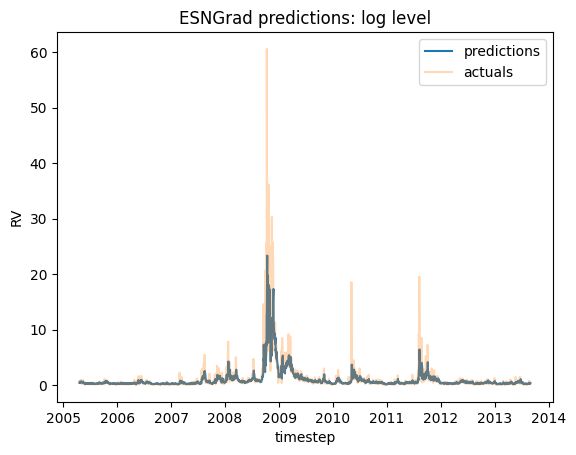

2it [04:29, 135.16s/it]

Run No: 2
Run Name test_2
Estimating the model...



2it [04:40, 135.16s/it]                                                                                                     

Early stopping at iteration 524 | best val loss 0.1961
Out of sample...


In [ ]:
from itertools import product

R_list = [25]
rho = [0.9]
leak_rates = [.3,]
gammas = [0.2, 0.25, 0.3, 0.35, 0.4, 0.5]
Ks = [100]

def qlike(actual, pred):
    r = actual/pred
    return torch.mean(r-torch.log(r)-1)

def mse(actual, pred):
    return torch.mean((actual-pred)**2)

def mae(actual, pred):
    return torch.mean(torch.abs(actual-pred))

iterator = list(product(Ks, R_list, rho, leak_rates, gammas))
results = {}

for i, param in tqdm(enumerate(iterator), total = len(iterator)):

    print('Run No:', i)
    run = f"test_{i}"
    print('Run Name', run)

    K, R, rho, leak_rate, gamma = param


    diffConfig = DiffusionConfig(num_timesteps = K, 
                    beta_1 = 1e-4, 
                    beta_K = 0.1,
                    mode = "linear",
                    s = 0.008,
                    process = 'ddpm'
                    )

    A = RandomWeightConfig(dist="normal", sparsity=0., norm_type="spectral_radius")
    C = RandomWeightConfig(dist="uniform", sparsity=0., norm_type="l2")
    zeta = RandomWeightConfig(dist="uniform", sparsity=0., norm_type="euclidean")

    esnConfig = ESNConfig(reservoir_size = R, 
                    A = A, 
                    C = C,
                    zeta = zeta,
                    leak_rate = leak_rate, 
                    rho = rho, 
                    gamma = gamma, 
                    omega = 0)

    denoiserConfig = DenoiserConfig("simple_mlp", {"dim_hids": [32, 32], "time_dim": 128})

    train_spec = TrainConfig(t0 = t0,                            
        batch_size = 526,
        lr = 1e-3,
        max_iters = 1000,
        val_fraction = 0.25, 
        eval_every = 1,
        patience = 100,  
        ema_decay = 0.99,  
        grad_clip = 1.0,
        seed = 3245,
        device = "cpu")

    cfg = ExperimentConfig(name=run, 
                        in_dim=1,
                        n_covariates = 0,
                        esn = esnConfig,
                        denoiser = denoiserConfig,
                        diffusion = diffConfig,
                        train = train_spec
                        )

    cfg.to_yaml(save_dir / (run + '.yaml'))

    model = ESNGrad(diff=build_diffusion(cfg), esn=build_esn(cfg),
                    denoiser=build_denoiser(cfg), spec=cfg.train)

    print('Estimating the model...')
    loss, time = model.fit(x = rv_train, c = None)

    print('Out of sample...')
    forecast = model.one_step_ahead_forecast(x_train = rv_train, 
                                         x_test = rv_test,
                                         chunk_size = 200, 
                                         n_samples = 100)

    F_m = forecast.squeeze(2).mean(dim = 1)

    if LOG:
        F = torch.exp(F_m)
        test = torch.exp(rv_test)
    else: 
        F = F_m.clone()
        test = rv_test.clone()

    mse_test = mse(test.squeeze(1), F).item()
    mae_test = mae(test.squeeze(1), F).item()
    qlike_test = qlike(test.squeeze(1), F).item()

    results[run] = [K, R, rho, leak_rate, gamma, qlike_test, mse_test, mae_test]

    print('Result of run ', i)
    print(param)
    print('MSE of the test:', mse_test)
    print('MAE of the test:', mae_test)
    print('QLIKE of the test:', qlike_test)

    predictions_df = pd.DataFrame({'predictions' : F.detach().numpy().flatten(), 
                               'true' : test.detach().numpy().flatten()}, 
                            index = dates_test
                            )

    plt.title('ESNGrad predictions: log level')
    plt.plot(predictions_df.index, predictions_df['predictions'], label = 'predictions')
    plt.plot(predictions_df.index, predictions_df['true'], label = 'actuals', alpha = 0.3)
    plt.ylabel('RV')
    plt.xlabel('timestep')
    plt.legend()
    plt.show()


In [24]:
results = pd.DataFrame(results, index = ['K', 'R', 'rho', 'leak_rate', 'gamma', 'qlike_test', 'mse_test', 'mae_test'])
# results.to_csv(save_dir / 'results.csv')
results

,test_0,test_1,test_2,test_3
K,100.000000,100.000000,100.000000,100.000000
R,25.000000,25.000000,25.000000,25.000000
rho,0.900000,0.900000,0.900000,0.900000
leak_rate,0.300000,0.300000,0.300000,0.300000
gamma,0.200000,0.250000,0.300000,0.350000
qlike_test,0.146536,0.147141,0.155347,0.145864
mse_test,3.574331,3.599566,4.075506,3.515114
mae_test,0.478982,0.478383,0.491879,0.474620


# Simple Test - ESN

Here we test using a simple ESN one-step ahead

In [ ]:
from rcdiff.data.rv import RVSP500
from rcdiff import ESN 
from rcdiff import RandomWeight, ParametersESN
from rcdiff.models.config import ESNConfig, build_esn, RandomWeightConfig


T, N = rv_train.shape

A = RandomWeight(dist="normal", sparsity=0, norm_type="spectral_radius")
C = RandomWeight(dist="uniform", sparsity=0, norm_type="l2")
zeta = RandomWeight(dist="uniform", sparsity=0, norm_type="euclidean")

esnConfig = ParametersESN(
                A_RW = A, 
                C_RW = C,
                zeta_RW = zeta,
                leak_rate = 0.2, 
                rho = 0.9, 
                gamma = 0.6,
                omega = 0.4)
esn = ESN(reservoir_size = 25, params= esnConfig, in_dim = N)


N_train = 2000
x_all = torch.cat([rv_train,rv_test], dim = 0).float() 
s = esn.get_states(x_all)          

ones = lambda a: torch.cat([a, torch.ones(len(a), 1)], 1)
Xtr, ytr = ones(s[:N_train-1]), x_all[1:N_train]  
lam = 1e-4
W = torch.linalg.solve(Xtr.T @ Xtr + lam * torch.eye(Xtr.shape[1]), Xtr.T @ ytr)

pred   = ones(s[N_train-1:-1]) @ W    
y_test = x_all[N_train:]
# print(pred.shape, y_test.shape)        
mse = ((pred - y_test) ** 2).mean().item()
print("MSE:", mse)

MSE: 0.267855703830719


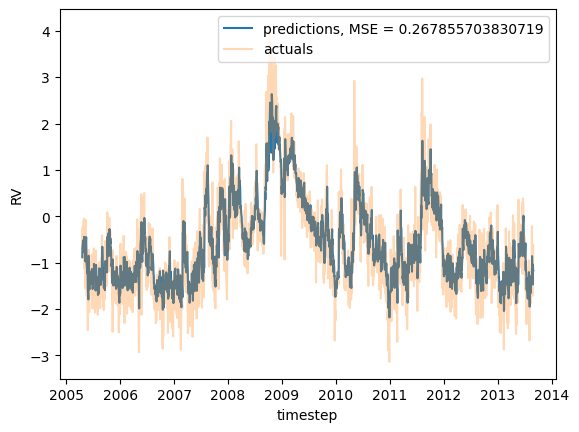

In [234]:
import matplotlib.pyplot as plt 

plt.plot(dates_test, pred.detach().numpy(), label = f'predictions, MSE = {mse}')
plt.plot(dates_test, rv_test.detach().numpy(), label = 'actuals', alpha = 0.3)
plt.ylabel('RV')
plt.xlabel('timestep')
plt.legend()
plt.show()